# 02 — 3GPP TR 38.901 TDL, CDL, and antenna diagnostics

**Purpose.** Explore the packaged TR 38.901 V16.1.0 delay-line tables and
antenna-aware channel models. The resources are transcription- and sanity-tested
but remain marked `pending_independent_review`; this notebook is not a formal
conformance claim.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Inspect the versioned TDL and CDL resources

In [2]:
from channel_dataset.channels.wireless.tr38901 import load_cdl_profile, load_tdl_profile

names = "ABCDE"
tdl_profiles = [load_tdl_profile(f"TDL-{name}") for name in names]
cdl_profiles = [load_cdl_profile(f"CDL-{name}") for name in names]
rows = []
for tdl, cdl in zip(tdl_profiles, cdl_profiles, strict=True):
    tdl_power = np.sum(10.0 ** (np.asarray(tdl.powers_db) / 10.0))
    cdl_power = np.sum(10.0 ** (np.asarray(cdl.powers_db) / 10.0))
    rows.append((tdl.name, len(tdl.delays), tdl.review_status, cdl.name, len(cdl.delays), cdl.metadata["review_status"], tdl_power, cdl_power))

print("profile | TDL taps | CDL clusters | review status")
for row in rows:
    print(f"{row[0]}/{row[3]:5s} | {row[1]:8d} | {row[4]:12d} | {row[2]}")
assert all(np.all(np.asarray(profile.delays) >= 0.0) for profile in tdl_profiles)
assert all(profile.review_status == "pending_independent_review" for profile in tdl_profiles)

profile | TDL taps | CDL clusters | review status
TDL-A/CDL-A |       23 |           23 | pending_independent_review
TDL-B/CDL-B |       23 |           23 | pending_independent_review
TDL-C/CDL-C |       24 |           24 | pending_independent_review
TDL-D/CDL-D |       14 |           13 | pending_independent_review
TDL-E/CDL-E |       15 |           14 | pending_independent_review


## 2. Sample configured TDL-C and inspect Doppler evolution

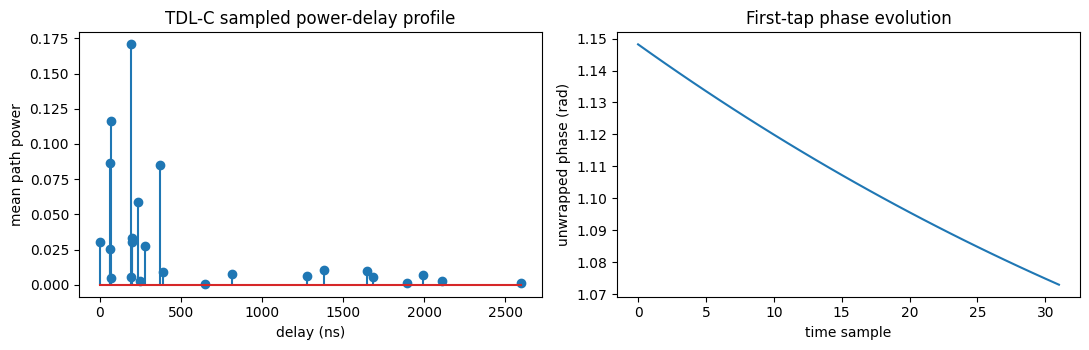

TDL CIR: (1, 1, 1, 1, 1, 24, 32) OFDM: (1, 1, 1, 1, 1, 32, 32)


In [3]:
from channel_dataset.channels.wireless import ChannelSamplingRequest
from channel_dataset.channels.wireless.tr38901 import register_tdl_model
from channel_dataset.channels.wireless.transforms import cir_to_ofdm, subcarrier_frequencies
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

tdl_envelope = load_config(ROOT / "configs/wireless/example_tdl.yaml")
tdl_registry = ModelRegistry()
register_tdl_model(tdl_registry)
tdl_model = tdl_registry.create(tdl_envelope)

def tdl_request():
    return ChannelSamplingRequest(1, 32, 30_720.0, execution, execution.random_stream(2201), "tdl-c")

tdl_cir = tdl_model.realize(tdl_request())
tdl_replay = tdl_model.realize(tdl_request())
tdl_ofdm = cir_to_ofdm(tdl_cir, subcarrier_frequencies(32, 15_000.0, execution))

assert torch.equal(tdl_cir.coefficients, tdl_replay.coefficients)
assert torch.all(tdl_cir.delays_s >= 0.0)
assert torch.isfinite(tdl_ofdm.coefficients).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
path_power = torch.mean(torch.abs(tdl_cir.coefficients[0, 0, 0, 0, 0]) ** 2, dim=-1)
axes[0].stem(as_numpy(tdl_cir.delays_s[0, 0, 0]) * 1e9, as_numpy(path_power))
axes[0].set(title="TDL-C sampled power-delay profile", xlabel="delay (ns)", ylabel="mean path power")
axes[1].plot(np.unwrap(np.angle(as_numpy(tdl_cir.coefficients[0, 0, 0, 0, 0, 0]))))
axes[1].set(title="First-tap phase evolution", xlabel="time sample", ylabel="unwrapped phase (rad)")
fig.tight_layout()
plt.show()
print("TDL CIR:", tdl_cir.shape, "OFDM:", tdl_ofdm.shape)

## 3. Sample CDL-C with diagnostic rays and polarized arrays

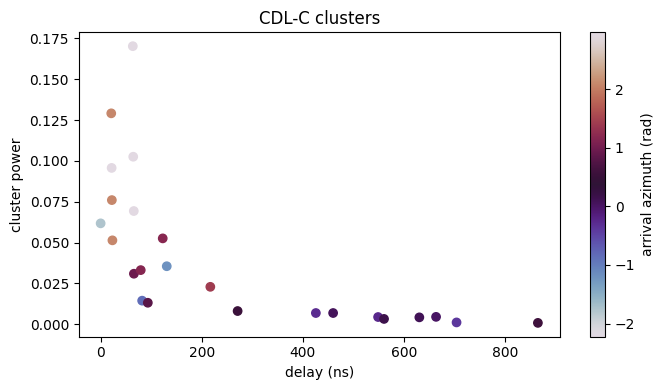

CDL CIR: (1, 1, 2, 1, 2, 24, 4) diagnostic rays: (1, 1, 1, 24, 20)
antenna counts (rx, tx): 2 2


In [4]:
from channel_dataset.channels.wireless.tr38901 import register_cdl_model

cdl_envelope = load_config(ROOT / "configs/wireless/example_cdl_polarized.yaml")
cdl_registry = ModelRegistry()
register_cdl_model(cdl_registry)
cdl_model = cdl_registry.create(cdl_envelope)
cdl_request = ChannelSamplingRequest(1, 4, 14_000.0, execution, execution.random_stream(2202), "cdl-c")
cdl_cir, rays = cdl_model.realize_with_rays(cdl_request)

active_cluster_power = (
    rays.powers_linear
    if rays.cluster_mask is None
    else torch.where(rays.cluster_mask, rays.powers_linear, 0.0)
)
assert torch.isfinite(cdl_cir.coefficients).all()
assert torch.all(rays.delays_s >= 0.0)
assert rays.shape[-1] == 20
assert abs(float(torch.sum(active_cluster_power)) - 1.0) < 1e-10

fig, ax = plt.subplots(figsize=(7, 4))
powers = as_numpy(rays.powers_linear[0, 0, 0])
delays = as_numpy(rays.delays_s[0, 0, 0]) * 1e9
mask = (
    np.ones_like(powers, dtype=bool)
    if rays.cluster_mask is None
    else as_numpy(rays.cluster_mask[0, 0, 0]).astype(bool)
)
scatter = ax.scatter(delays[mask], powers[mask], c=as_numpy(rays.clusters.azimuth_arrival_rad[0, 0, 0])[mask], cmap="twilight")
ax.set(title="CDL-C clusters", xlabel="delay (ns)", ylabel="cluster power")
fig.colorbar(scatter, ax=ax, label="arrival azimuth (rad)")
fig.tight_layout()
plt.show()
print("CDL CIR:", cdl_cir.shape, "diagnostic rays:", rays.shape)
print("antenna counts (rx, tx):", cdl_cir.shape[2], cdl_cir.shape[4])

## 4. Inspect a standard antenna element pattern

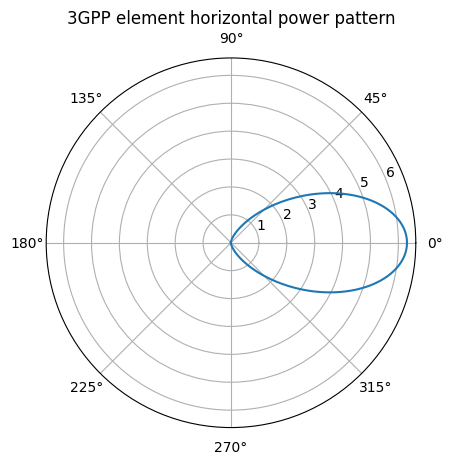

Boresight is at 0 rad; attenuation is symmetric around boresight.


In [5]:
from channel_dataset.channels.wireless.antennas import ThreeGPPAntennaElement
from channel_dataset.channels.wireless.antennas.visualization import plot_horizontal_power_pattern

axes = plot_horizontal_power_pattern(ThreeGPPAntennaElement())
axes.set_title("3GPP element horizontal power pattern")
plt.show()
print("Boresight is at 0 rad; attenuation is symmetric around boresight.")

## Manual check and next experiments

- Compare A–E delay/power tables and the specular components in TDL/CDL D and E.
- Increase speed and verify faster phase evolution without changing path delays.
- Switch between SISO, dual-polarized, and 8×8 packaged antenna layouts.
- Use `select_paths` on one diagnostic link when scalar path objects aid inspection.